<a href="https://colab.research.google.com/github/klvskarthik/CSA47-Deep-learning-/blob/main/CSA47-LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Customer-Genre Matrix:
 [[5 1 2 4 3]
 [4 2 1 5 2]
 [1 5 4 2 3]
 [2 4 5 1 4]
 [5 1 2 4 2]
 [1 4 5 2 3]]

Genre-Book Matrix:
 [[0.9 0.2 0.1 0.4]
 [0.1 0.9 0.3 0.2]
 [0.2 0.3 0.9 0.1]
 [0.8 0.1 0.2 0.9]
 [0.3 0.5 0.4 0.7]]

Dot Product: 9.100000000000001

Customer-Book Score Matrix:
 [[9.1 4.4 4.6 8.1]
 [8.6 4.4 3.7 8. ]
 [4.7 7.6 6.8 5.7]
 [5.2 7.6 7.7 5.8]
 [8.8 3.9 4.2 7.4]
 [4.8 7.  7.4 5.6]]

Transpose of Customer Matrix:
 [[5 4 1 2 5 1]
 [1 2 5 4 1 4]
 [2 1 4 5 2 5]
 [4 5 2 1 4 2]
 [3 2 3 4 2 3]]

Pseudoinverse of Customer Matrix:
 [[-3.12500000e-01 -2.29166667e-01  2.70833333e-01  1.87500000e-01
   6.66666667e-01 -5.00000000e-01]
 [-3.95833333e-01  2.08333333e-02  5.20833333e-01  1.04166667e-01
   3.33333333e-01 -5.00000000e-01]
 [-1.45833333e-01 -2.29166667e-01 -2.29166667e-01 -1.45833333e-01
   3.33333333e-01  5.00000000e-01]
 [ 1.87500000e-01  2.70833333e-01 -2.29166667e-01 -3.12500000e-01
  -3.33333333e-01  5.00000000e-01]
 [ 7.50000000e-01  2.50000000e-01 -2.50000000e-01  2.50

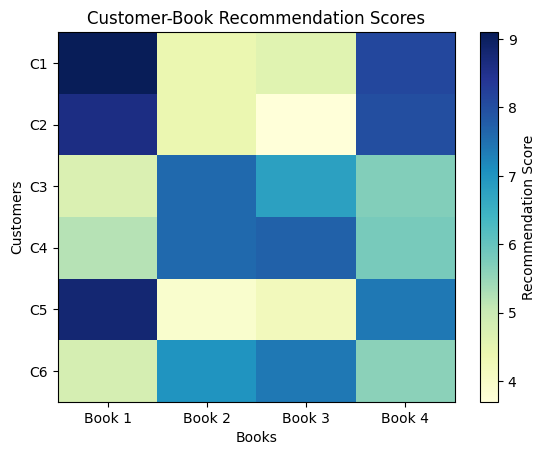

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Customer-Genre Matrix (6x5)
C = np.array([
    [5, 1, 2, 4, 3],
    [4, 2, 1, 5, 2],
    [1, 5, 4, 2, 3],
    [2, 4, 5, 1, 4],
    [5, 1, 2, 4, 2],
    [1, 4, 5, 2, 3]
])

# 2. Genre-Book Matrix (5x4)
B = np.array([
    [0.9, 0.2, 0.1, 0.4],
    [0.1, 0.9, 0.3, 0.2],
    [0.2, 0.3, 0.9, 0.1],
    [0.8, 0.1, 0.2, 0.9],
    [0.3, 0.5, 0.4, 0.7]
])

print("Customer-Genre Matrix:\n", C)
print("\nGenre-Book Matrix:\n", B)

# 3. Dot Product
print("\nDot Product:", np.dot(C[0], B[:, 0]))

# 4. Matrix Multiplication
S = np.dot(C, B)
print("\nCustomer-Book Score Matrix:\n", S)

# 5. Transpose
print("\nTranspose of Customer Matrix:\n", C.T)

# 6. Inverse and Pseudoinverse
print("\nPseudoinverse of Customer Matrix:\n", np.linalg.pinv(C))

# 7. Element-wise Operations
print("\nAddition:\n", C + 1)
print("\nMultiplication:\n", C * C)

# 8. Cosine Similarity
norms = np.linalg.norm(C, axis=1)
similarity = (C @ C.T) / np.outer(norms, norms)

print("\nCosine Similarity Matrix:\n", np.round(similarity, 3))

# Find the two most similar different customers
np.fill_diagonal(similarity, -1)
i, j = np.unravel_index(np.argmax(similarity), similarity.shape)

print("\nMost Similar Customers:", i + 1, "and", j + 1)
print("Cosine Similarity:", round(similarity[i, j], 3))

# 9. Dense Layer: y = Wx + b
x = C[0]
W = B.T
bias = np.array([0.1, 0.2, 0.1, 0.3])

y = W @ x + bias

print("\nDense Layer Output:", y)
print("First Customer Scores:", S[0])

# 10. Heatmap
plt.imshow(S, cmap="YlGnBu", aspect="auto")
plt.colorbar(label="Recommendation Score")
plt.xlabel("Books")
plt.ylabel("Customers")
plt.xticks(range(4), ["Book 1", "Book 2", "Book 3", "Book 4"])
plt.yticks(range(6), ["C1", "C2", "C3", "C4", "C5", "C6"])
plt.title("Customer-Book Recommendation Scores")
plt.show()

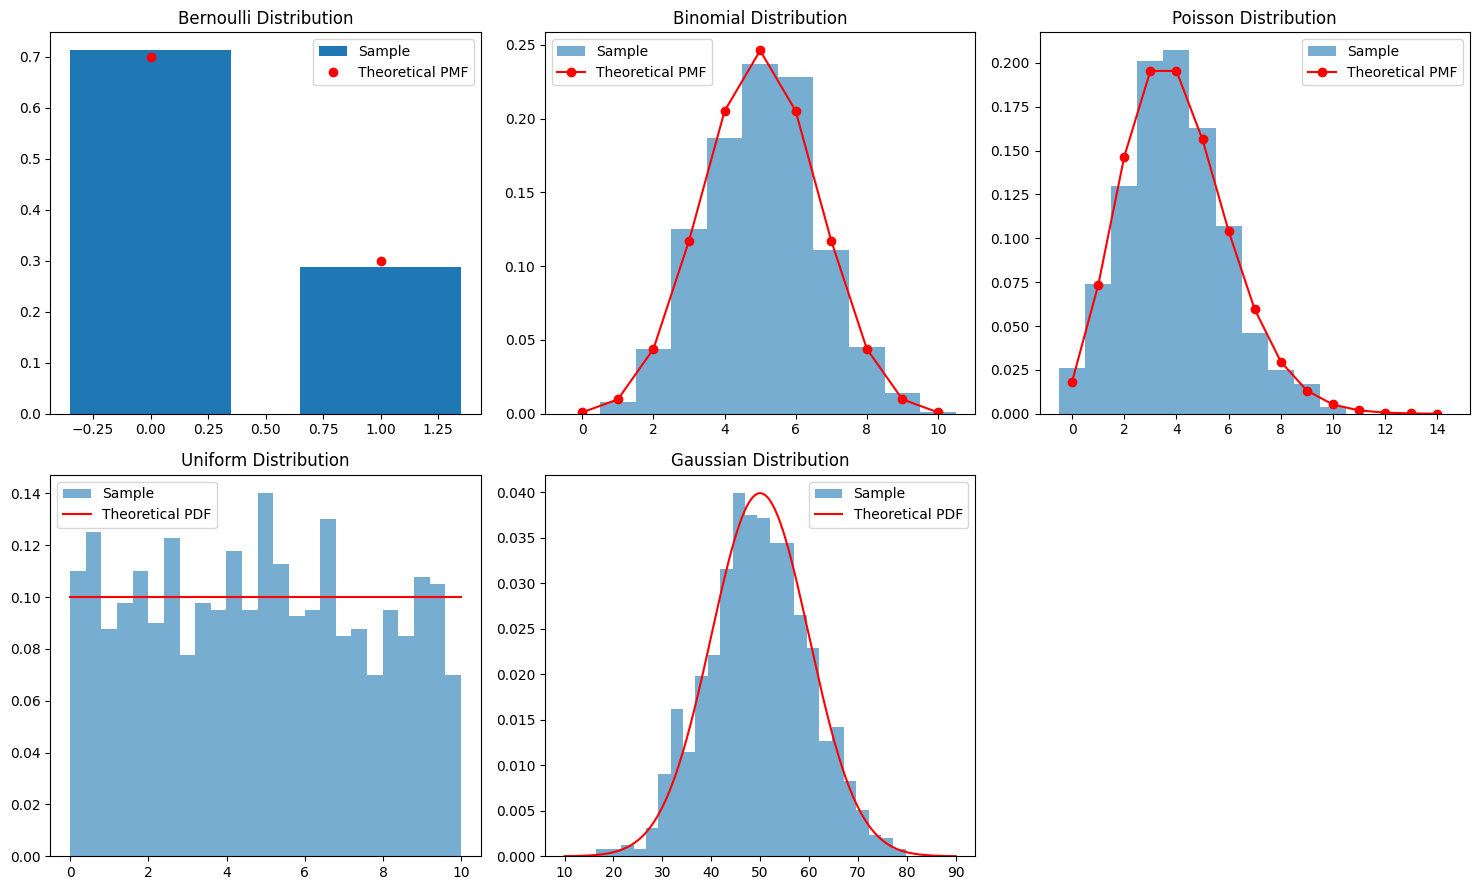

TASK 2: BAYES' THEOREM
Probability of disease given positive test: 8.76 %

TASK 3: SIMULATION
Total patients: 100000
Positive test results: 10867
True positive cases: 934
Empirical probability: 8.59 %
Theoretical probability: 8.76 %


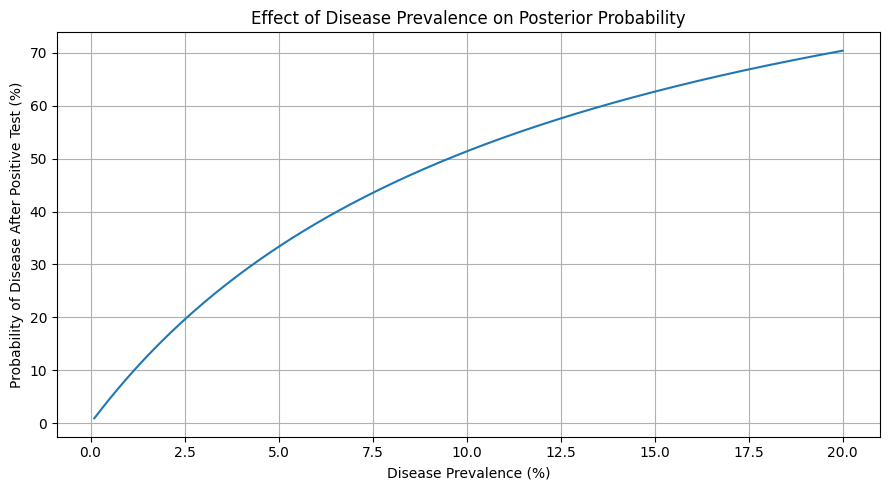


TASK 4: SELECTED PREVALENCE VALUES
Prevalence:   0.1% -> Posterior: 0.94%
Prevalence:   1.0% -> Posterior: 8.76%
Prevalence:   5.0% -> Posterior: 33.33%
Prevalence:  10.0% -> Posterior: 51.35%
Prevalence:  20.0% -> Posterior: 70.37%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bernoulli, binom, poisson, uniform, norm

np.random.seed(42)

# TASK 1: Generate and plot probability distributions

fig, ax = plt.subplots(2, 3, figsize=(15, 9))

# 1. Bernoulli Distribution
p = 0.3
data = bernoulli.rvs(p, size=1000)
x = np.array([0, 1])
ax[0, 0].hist(data, bins=[-0.5, 0.5, 1.5],
              density=True, rwidth=0.7, label="Sample")
ax[0, 0].plot(x, bernoulli.pmf(x, p), "ro", label="Theoretical PMF")
ax[0, 0].set_title("Bernoulli Distribution")
ax[0, 0].legend()

# 2. Binomial Distribution
n, p = 10, 0.5
data = binom.rvs(n, p, size=1000)
x = np.arange(0, n + 1)
ax[0, 1].hist(data, bins=np.arange(-0.5, n + 1.5),
              density=True, alpha=0.6, label="Sample")
ax[0, 1].plot(x, binom.pmf(x, n, p), "ro-", label="Theoretical PMF")
ax[0, 1].set_title("Binomial Distribution")
ax[0, 1].legend()

# 3. Poisson Distribution
lam = 4
data = poisson.rvs(lam, size=1000)
x = np.arange(0, 15)
ax[0, 2].hist(data, bins=np.arange(-0.5, 15.5),
              density=True, alpha=0.6, label="Sample")
ax[0, 2].plot(x, poisson.pmf(x, lam), "ro-", label="Theoretical PMF")
ax[0, 2].set_title("Poisson Distribution")
ax[0, 2].legend()

# 4. Uniform Distribution
data = uniform.rvs(loc=0, scale=10, size=1000)
x = np.linspace(0, 10, 200)
ax[1, 0].hist(data, bins=25, density=True, alpha=0.6, label="Sample")
ax[1, 0].plot(x, uniform.pdf(x, loc=0, scale=10),
              "r-", label="Theoretical PDF")
ax[1, 0].set_title("Uniform Distribution")
ax[1, 0].legend()

# 5. Gaussian (Normal) Distribution
data = norm.rvs(loc=50, scale=10, size=1000)
x = np.linspace(10, 90, 200)
ax[1, 1].hist(data, bins=25, density=True, alpha=0.6, label="Sample")
ax[1, 1].plot(x, norm.pdf(x, loc=50, scale=10),
              "r-", label="Theoretical PDF")
ax[1, 1].set_title("Gaussian Distribution")
ax[1, 1].legend()

ax[1, 2].axis("off")
plt.tight_layout()
plt.show()


# TASK 2: Bayes' Theorem

prevalence = 0.01
sensitivity = 0.95
specificity = 0.90

p_disease = prevalence
p_positive_given_disease = sensitivity
p_positive_given_no_disease = 1 - specificity

p_positive = (
    p_positive_given_disease * p_disease
    + p_positive_given_no_disease * (1 - p_disease)
)

posterior = (
    p_positive_given_disease * p_disease / p_positive
)

print("TASK 2: BAYES' THEOREM")
print("Probability of disease given positive test:",
      round(posterior * 100, 2), "%")


# TASK 3: Simulate 100,000 patients

N = 100000

disease = np.random.binomial(1, prevalence, N)

test_result = np.zeros(N, dtype=int)

# Positive result for patients with disease
test_result[disease == 1] = np.random.binomial(
    1, sensitivity, np.sum(disease == 1)
)

# Positive result for patients without disease
test_result[disease == 0] = np.random.binomial(
    1, 1 - specificity, np.sum(disease == 0)
)

positive_patients = np.sum(test_result == 1)
true_positives = np.sum((disease == 1) & (test_result == 1))

empirical = true_positives / positive_patients

print("\nTASK 3: SIMULATION")
print("Total patients:", N)
print("Positive test results:", positive_patients)
print("True positive cases:", true_positives)
print("Empirical probability:", round(empirical * 100, 2), "%")
print("Theoretical probability:", round(posterior * 100, 2), "%")


# TASK 4: Posterior probability for different prevalences

prevalences = np.linspace(0.001, 0.20, 200)

posteriors = (
    sensitivity * prevalences
    / (
        sensitivity * prevalences
        + (1 - specificity) * (1 - prevalences)
    )
)

plt.figure(figsize=(9, 5))
plt.plot(prevalences * 100, posteriors * 100)
plt.xlabel("Disease Prevalence (%)")
plt.ylabel("Probability of Disease After Positive Test (%)")
plt.title("Effect of Disease Prevalence on Posterior Probability")
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nTASK 4: SELECTED PREVALENCE VALUES")

for prev in [0.001, 0.01, 0.05, 0.10, 0.20]:
    post = (
        sensitivity * prev
        / (sensitivity * prev + (1 - specificity) * (1 - prev))
    )
    print(f"Prevalence: {prev * 100:5.1f}%"
          f" -> Posterior: {post * 100:.2f}%")

First five patient records:
   Haemoglobin       RBC   Glucose  Cholesterol       BMI
0    -0.441574 -0.260200 -0.465564    -1.004803  0.414728
1     1.496904  1.076639  0.319721    -0.700158 -0.651499
2    -0.843438  0.492678  1.120431     0.859733 -0.355540
3    -1.070800  0.023165  1.086252     0.863512  0.423373
4    -1.167675 -0.745998 -0.689502    -0.688291 -1.731105

Standardised data:
   Haemoglobin       RBC   Glucose  Cholesterol       BMI
0    -0.446175 -0.226154 -0.511745    -1.051709  0.385007
1     1.433335  1.114962  0.360797    -0.734446 -0.751827
2    -0.835815  0.529133  1.250477     0.890057 -0.436269
3    -1.056261  0.058118  1.212499     0.893993  0.394225
4    -1.150188 -0.713506 -0.760566    -0.722086 -1.902927

Covariance Matrix:
             Haemoglobin    RBC  Glucose  Cholesterol    BMI
Haemoglobin        1.000  0.691    0.247        0.049  0.079
RBC                0.691  1.000    0.180        0.094  0.091
Glucose            0.247  0.180    1.000        0.456

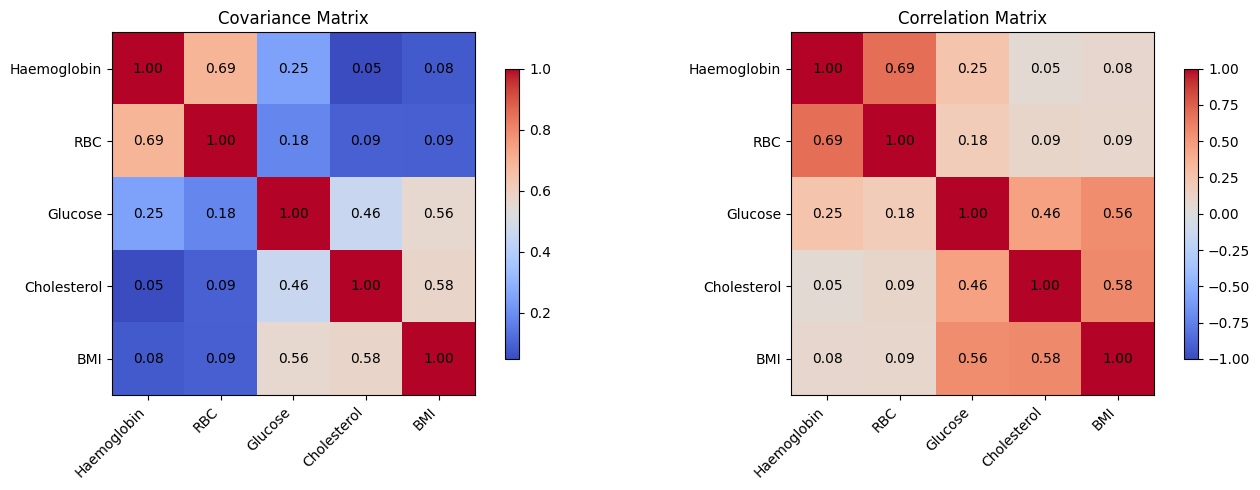


Eigenvalues:
[2.233 1.544 0.539 0.39  0.294]

Eigenvectors (columns):
[[-0.351  0.61   0.077 -0.048  0.704]
 [-0.347  0.603 -0.258  0.125 -0.659]
 [-0.526 -0.165  0.702 -0.392 -0.223]
 [-0.471 -0.344 -0.659 -0.463  0.103]
 [-0.507 -0.344  0.008  0.784  0.098]]


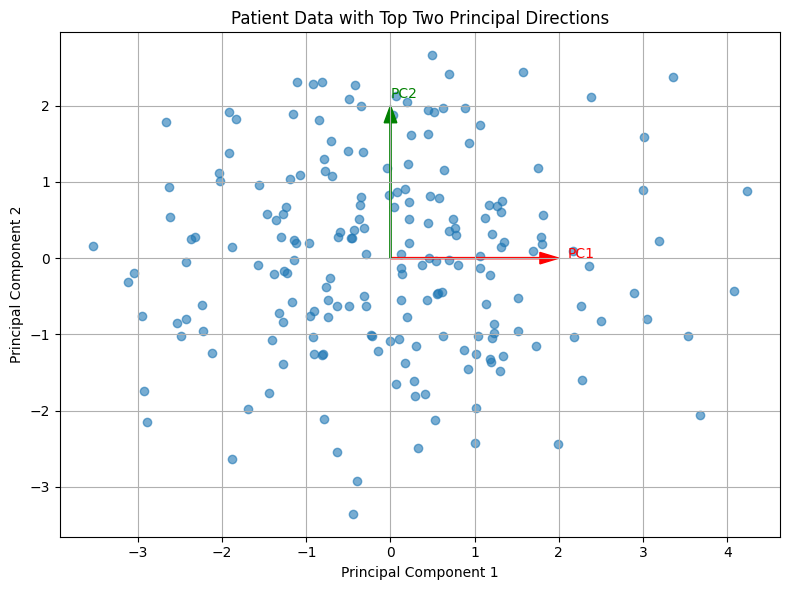


Variance Explained:
     Eigenvalue  Variance Explained (%)  Cumulative Variance (%)
PC1        2.23                   44.65                    44.65
PC2        1.54                   30.88                    75.53
PC3        0.54                   10.79                    86.31
PC4        0.39                    7.81                    94.12
PC5        0.29                    5.88                   100.00

Variance captured by first two components: 75.53 %


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TASK 1: Create dataset of 200 patients
np.random.seed(42)
n = 200

data = np.random.multivariate_normal(
    [0, 0, 0, 0, 0],
    [
        [1, 0.7, 0.2, 0.1, 0.1],
        [0.7, 1, 0.2, 0.1, 0.1],
        [0.2, 0.2, 1, 0.5, 0.6],
        [0.1, 0.1, 0.5, 1, 0.6],
        [0.1, 0.1, 0.6, 0.6, 1]
    ],
    size=n
)

df = pd.DataFrame(data, columns=[
    "Haemoglobin", "RBC", "Glucose", "Cholesterol", "BMI"
])

print("First five patient records:")
print(df.head())

# Standardise each feature
X = (df - df.mean()) / df.std(ddof=1)

print("\nStandardised data:")
print(X.head())


# TASK 2: Covariance and correlation matrices

cov_matrix = X.cov()
corr_matrix = X.corr()

print("\nCovariance Matrix:")
print(cov_matrix.round(3))

print("\nCorrelation Matrix:")
print(corr_matrix.round(3))

# Covariance heatmap
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

im1 = ax[0].imshow(cov_matrix, cmap="coolwarm")
ax[0].set_title("Covariance Matrix")
ax[0].set_xticks(range(5))
ax[0].set_yticks(range(5))
ax[0].set_xticklabels(X.columns, rotation=45, ha="right")
ax[0].set_yticklabels(X.columns)

for i in range(5):
    for j in range(5):
        ax[0].text(j, i, f"{cov_matrix.iloc[i, j]:.2f}",
                   ha="center", va="center")

fig.colorbar(im1, ax=ax[0], shrink=0.8)

# Correlation heatmap
im2 = ax[1].imshow(corr_matrix, cmap="coolwarm",
                   vmin=-1, vmax=1)
ax[1].set_title("Correlation Matrix")
ax[1].set_xticks(range(5))
ax[1].set_yticks(range(5))
ax[1].set_xticklabels(X.columns, rotation=45, ha="right")
ax[1].set_yticklabels(X.columns)

for i in range(5):
    for j in range(5):
        ax[1].text(j, i, f"{corr_matrix.iloc[i, j]:.2f}",
                   ha="center", va="center")

fig.colorbar(im2, ax=ax[1], shrink=0.8)
plt.tight_layout()
plt.show()


# TASK 3: Eigenvalues and eigenvectors

cov = cov_matrix.to_numpy()

eigenvalues, eigenvectors = np.linalg.eigh(cov)

# Sort eigenvalues in descending order
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print("\nEigenvalues:")
print(np.round(eigenvalues, 3))

print("\nEigenvectors (columns):")
print(np.round(eigenvectors, 3))


# TASK 4: Project data into 2-D and draw principal directions

X_array = X.to_numpy()

# Project data onto the first two principal components
scores = X_array @ eigenvectors[:, :2]

plt.figure(figsize=(8, 6))
plt.scatter(scores[:, 0], scores[:, 1], alpha=0.6)

# Draw the top two eigenvector directions in PCA space
plt.arrow(0, 0, 2, 0, color="red",
          width=0.015, head_width=0.15, length_includes_head=True)
plt.arrow(0, 0, 0, 2, color="green",
          width=0.015, head_width=0.15, length_includes_head=True)

plt.text(2.1, 0, "PC1", color="red")
plt.text(0, 2.1, "PC2", color="green")

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Patient Data with Top Two Principal Directions")
plt.grid(True)
plt.tight_layout()
plt.show()


# TASK 5: Percentage of variance explained

variance_percent = eigenvalues / np.sum(eigenvalues) * 100
cumulative_percent = np.cumsum(variance_percent)

results = pd.DataFrame({
    "Eigenvalue": eigenvalues,
    "Variance Explained (%)": variance_percent,
    "Cumulative Variance (%)": cumulative_percent
}, index=["PC1", "PC2", "PC3", "PC4", "PC5"])

print("\nVariance Explained:")
print(results.round(2))

print("\nVariance captured by first two components:",
      round(cumulative_percent[1], 2), "%")

True Weather Distribution: [0.5 0.3 0.2]

TASK 1: Entropy
Entropy = 1.4855 bits

TASK 2: Model Comparison
Model 1 Cross-Entropy = 1.5159
Model 1 KL Divergence = 0.0304
Model 2 Cross-Entropy = 1.6125
Model 2 KL Divergence = 0.127

TASK 3: Verification
Model 1: H + KL = 1.5159
Model 1: Cross-Entropy = 1.5159
Model 2: H + KL = 1.6125
Model 2: Cross-Entropy = 1.6125

TASK 4: KL Asymmetry
KL(P || Q1) = 0.0304
KL(Q1 || P) = 0.0298


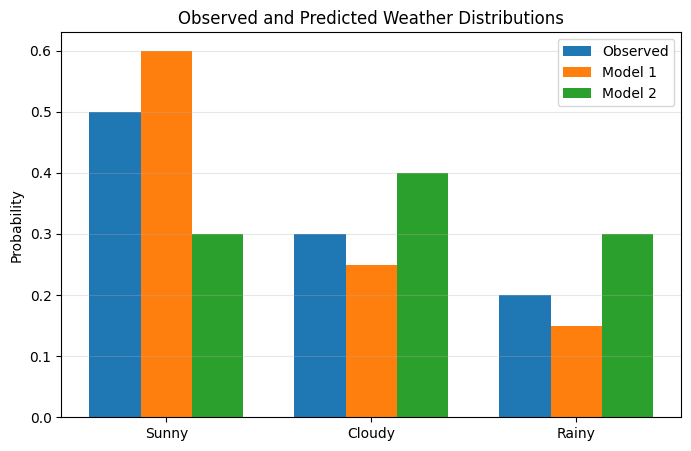

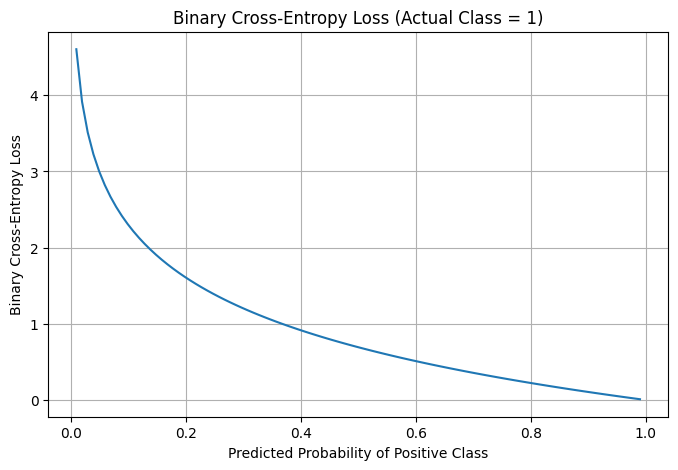


TASK 5: Binary Cross-Entropy
Loss at predicted probability 0.9 = 0.1054


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy

# TASK 1: Observed weather for 30 days
weather = ["Sunny", "Cloudy", "Rainy"]

observed = np.array([15, 9, 6])
P = observed / observed.sum()

print("True Weather Distribution:", P)

# Two forecasting models
Q1 = np.array([0.60, 0.25, 0.15])
Q2 = np.array([0.30, 0.40, 0.30])

# Entropy of the true distribution
H = entropy(P, base=2)

print("\nTASK 1: Entropy")
print("Entropy =", round(H, 4), "bits")


# TASK 2: Cross-entropy and KL divergence
def cross_entropy(P, Q):
    return -np.sum(P * np.log2(Q))

CE1 = cross_entropy(P, Q1)
CE2 = cross_entropy(P, Q2)

KL1 = entropy(P, Q1, base=2)
KL2 = entropy(P, Q2, base=2)

print("\nTASK 2: Model Comparison")
print("Model 1 Cross-Entropy =", round(CE1, 4))
print("Model 1 KL Divergence =", round(KL1, 4))
print("Model 2 Cross-Entropy =", round(CE2, 4))
print("Model 2 KL Divergence =", round(KL2, 4))


# TASK 3: Verify the relationship
print("\nTASK 3: Verification")
print("Model 1: H + KL =", round(H + KL1, 4))
print("Model 1: Cross-Entropy =", round(CE1, 4))

print("Model 2: H + KL =", round(H + KL2, 4))
print("Model 2: Cross-Entropy =", round(CE2, 4))


# TASK 4: KL Divergence is asymmetric
KL_PQ = entropy(P, Q1, base=2)
KL_QP = entropy(Q1, P, base=2)

print("\nTASK 4: KL Asymmetry")
print("KL(P || Q1) =", round(KL_PQ, 4))
print("KL(Q1 || P) =", round(KL_QP, 4))


# Plot weather distributions
x = np.arange(len(weather))
width = 0.25

plt.figure(figsize=(8, 5))
plt.bar(x - width, P, width, label="Observed")
plt.bar(x, Q1, width, label="Model 1")
plt.bar(x + width, Q2, width, label="Model 2")

plt.xticks(x, weather)
plt.ylabel("Probability")
plt.title("Observed and Predicted Weather Distributions")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()


# TASK 5: Binary cross-entropy loss
y_true = 1

predicted = np.linspace(0.01, 0.99, 100)

loss = -(
    y_true * np.log(predicted)
    + (1 - y_true) * np.log(1 - predicted)
)

plt.figure(figsize=(8, 5))
plt.plot(predicted, loss)
plt.xlabel("Predicted Probability of Positive Class")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Binary Cross-Entropy Loss (Actual Class = 1)")
plt.grid(True)
plt.show()

print("\nTASK 5: Binary Cross-Entropy")
print("Loss at predicted probability 0.9 =",
      round(-np.log(0.9), 4))

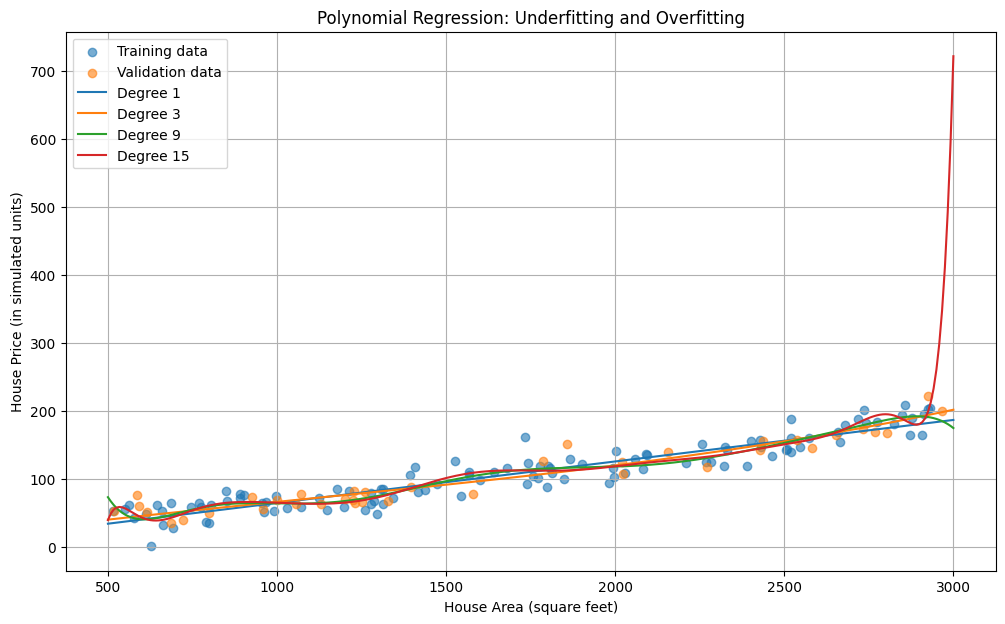

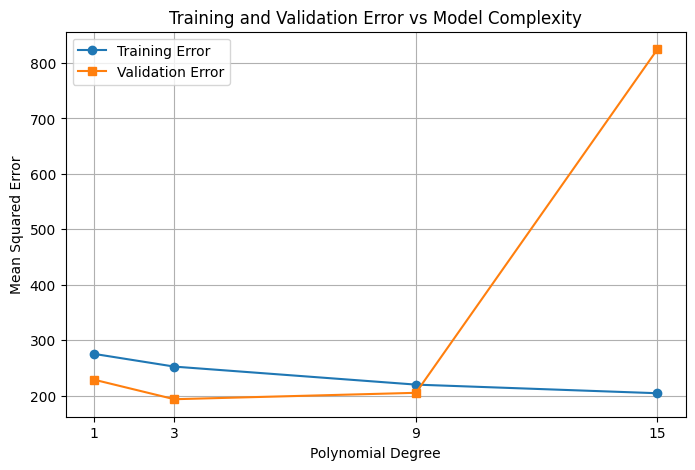

Degree | Training MSE | Validation MSE
     1 |       275.16 |         228.65
     3 |       252.14 |         193.29
     9 |       219.66 |         204.84
    15 |       204.09 |         824.89

Bias-Variance Analysis
Degree | Bias^2 | Variance
     1 |   22.62 |     3.97
     3 |    0.04 |     6.33
     9 |    0.23 |    21.72
    15 |    0.81 |    75.61


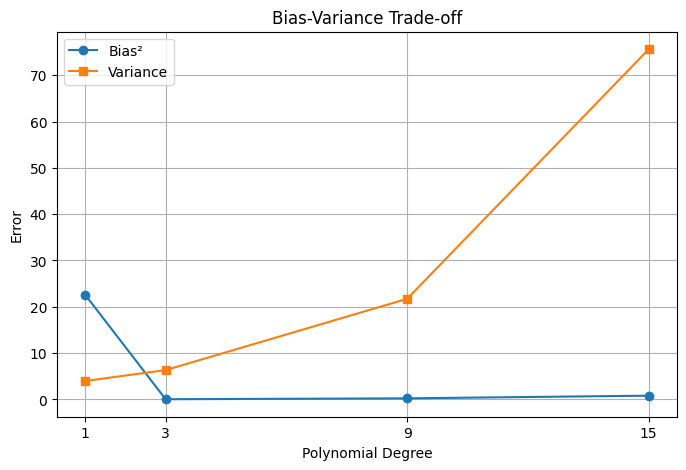


Best Polynomial Degree: 3
Lowest Validation MSE: 193.29


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

np.random.seed(42)

# TASK 1: Generate 150 house samples
n = 150
area = np.random.uniform(500, 3000, n)

# Hidden nonlinear relationship
true_price = 30 + 0.025 * area + 0.00001 * area**2
price = true_price + np.random.normal(0, 15, n)

X = ((area - 1750) / 1250).reshape(-1, 1)
y = price

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=42
)

degrees = [1, 3, 9, 15]
train_errors = []
val_errors = []

# TASK 2: Fit and plot polynomial regression curves
x_plot = np.linspace(-1, 1, 300).reshape(-1, 1)
area_plot = x_plot.flatten() * 1250 + 1750

plt.figure(figsize=(12, 7))
plt.scatter(X_train.flatten() * 1250 + 1750,
            y_train, label="Training data", alpha=0.6)
plt.scatter(X_val.flatten() * 1250 + 1750,
            y_val, label="Validation data", alpha=0.6)

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_errors.append(mean_squared_error(y_train, train_pred))
    val_errors.append(mean_squared_error(y_val, val_pred))

    y_curve = model.predict(x_plot)
    plt.plot(area_plot, y_curve, label=f"Degree {degree}")

plt.xlabel("House Area (square feet)")
plt.ylabel("House Price (in simulated units)")
plt.title("Polynomial Regression: Underfitting and Overfitting")
plt.legend()
plt.grid(True)
plt.show()


# TASK 3: Plot training and validation errors
plt.figure(figsize=(8, 5))
plt.plot(degrees, train_errors, "o-", label="Training Error")
plt.plot(degrees, val_errors, "s-", label="Validation Error")
plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.title("Training and Validation Error vs Model Complexity")
plt.xticks(degrees)
plt.legend()
plt.grid(True)
plt.show()

print("Degree | Training MSE | Validation MSE")
for d, tr, va in zip(degrees, train_errors, val_errors):
    print(f"{d:6} | {tr:12.2f} | {va:14.2f}")


# TASK 4: Estimate bias squared and variance by repeated resampling
np.random.seed(123)

x_grid = np.linspace(-1, 1, 100).reshape(-1, 1)
true_grid_price = (
    30 + 0.025 * (x_grid.flatten() * 1250 + 1750)
    + 0.00001 * (x_grid.flatten() * 1250 + 1750)**2
)

n_repeats = 100
bias_squared = []
variances = []

for degree in degrees:
    predictions = []

    for _ in range(n_repeats):
        # Generate a new noisy dataset
        area_sample = np.random.uniform(500, 3000, n)
        true_sample = (
            30 + 0.025 * area_sample + 0.00001 * area_sample**2
        )
        price_sample = true_sample + np.random.normal(0, 15, n)

        X_sample = ((area_sample - 1750) / 1250).reshape(-1, 1)

        model = make_pipeline(
            PolynomialFeatures(degree),
            LinearRegression()
        )
        model.fit(X_sample, price_sample)
        predictions.append(model.predict(x_grid))

    predictions = np.array(predictions)
    mean_prediction = predictions.mean(axis=0)

    bias_squared.append(
        np.mean((mean_prediction - true_grid_price)**2)
    )
    variances.append(np.mean(np.var(predictions, axis=0)))

print("\nBias-Variance Analysis")
print("Degree | Bias^2 | Variance")
for d, b, v in zip(degrees, bias_squared, variances):
    print(f"{d:6} | {b:7.2f} | {v:8.2f}")

plt.figure(figsize=(8, 5))
plt.plot(degrees, bias_squared, "o-", label="Bias²")
plt.plot(degrees, variances, "s-", label="Variance")
plt.xlabel("Polynomial Degree")
plt.ylabel("Error")
plt.title("Bias-Variance Trade-off")
plt.xticks(degrees)
plt.legend()
plt.grid(True)
plt.show()


# TASK 5: Select the best degree using validation error
best_index = np.argmin(val_errors)
best_degree = degrees[best_index]

print("\nBest Polynomial Degree:", best_degree)
print("Lowest Validation MSE:", round(val_errors[best_index], 2))

Final loss - Batch GD: 0.001495
Final loss - SGD: 0.004338
Final loss - Momentum: 0.052042


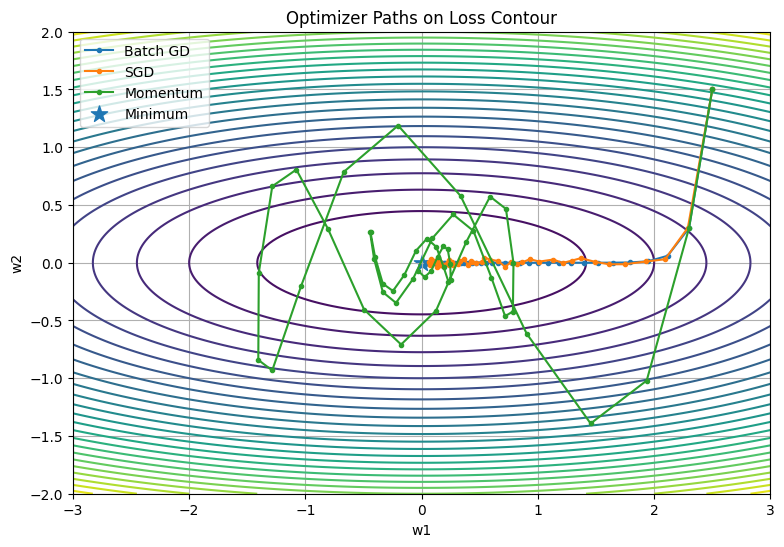

SGD
Final training loss: 0.0336
Test loss: 0.0375

SGD + Momentum
Final training loss: 0.0286
Test loss: 0.0318

Adam
Final training loss: 0.0264
Test loss: 0.0298



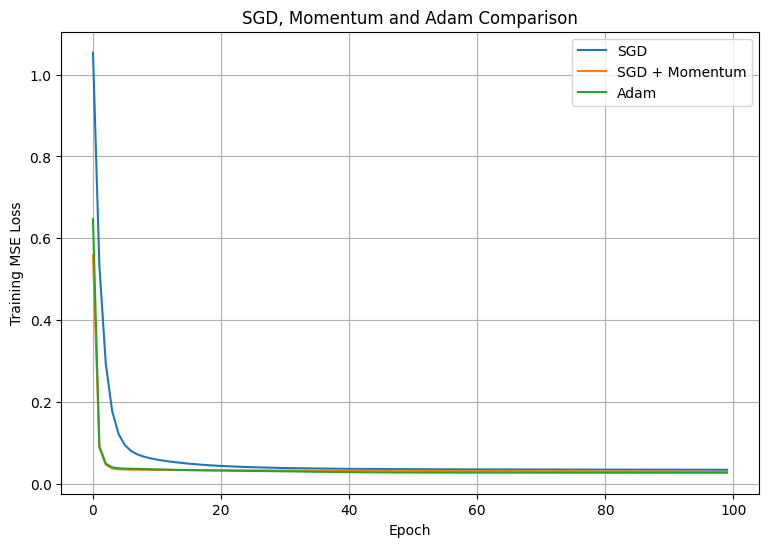

Learning rate: 0.0001
Initial loss: 1.5012
Final loss: 0.9403
Observation: Converged

Learning rate: 0.01
Initial loss: 0.9932
Final loss: 0.0357
Observation: Converged

Learning rate: 1.0
Initial loss: nan
Final loss: nan
Observation: Diverged (non-finite loss)



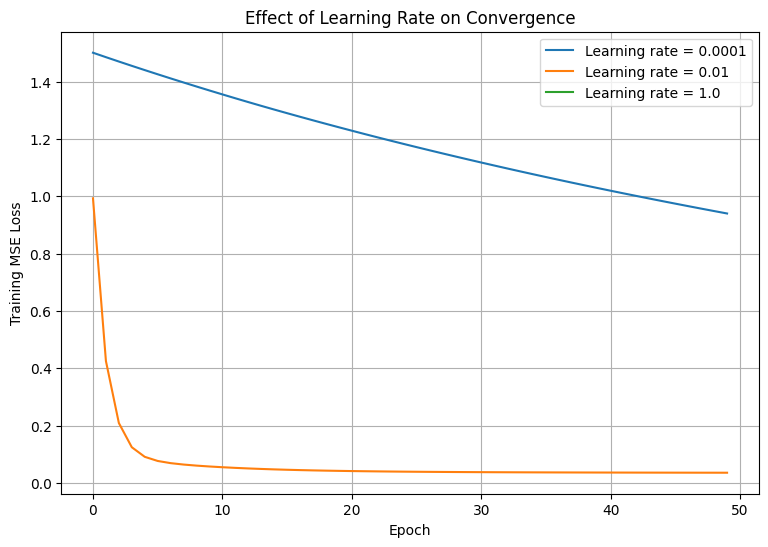

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
tf.random.set_seed(42)

# ==================================================
# TASK 1: Implement optimizers from scratch
# ==================================================

# Loss function: L(x, y) = x^2 + 10y^2

def loss_function(w):
    return w[0]**2 + 10 * w[1]**2

def gradient(w):
    return np.array([2 * w[0], 20 * w[1]])

def batch_gd(start, lr, steps):
    w = np.array(start, dtype=float)
    path = [w.copy()]

    for _ in range(steps):
        w = w - lr * gradient(w)
        path.append(w.copy())

    return np.array(path)

def sgd(start, lr, steps):
    w = np.array(start, dtype=float)
    path = [w.copy()]

    for _ in range(steps):
        # Stochastic gradient estimate with noise
        g = gradient(w) + np.random.normal(0, 0.5, 2)
        w = w - lr * g
        path.append(w.copy())

    return np.array(path)

def momentum(start, lr, steps, beta=0.9):
    w = np.array(start, dtype=float)
    velocity = np.zeros(2)
    path = [w.copy()]

    for _ in range(steps):
        velocity = beta * velocity + gradient(w)
        w = w - lr * velocity
        path.append(w.copy())

    return np.array(path)


# Generate optimization paths
start = [2.5, 1.5]
path_gd = batch_gd(start, 0.04, 50)
path_sgd = sgd(start, 0.04, 50)
path_momentum = momentum(start, 0.04, 50)

print("Final loss - Batch GD:",
      round(loss_function(path_gd[-1]), 6))
print("Final loss - SGD:",
      round(loss_function(path_sgd[-1]), 6))
print("Final loss - Momentum:",
      round(loss_function(path_momentum[-1]), 6))


# ==================================================
# TASK 2: Plot optimizer paths on a 2-D contour
# ==================================================

x = np.linspace(-3, 3, 200)
y = np.linspace(-2, 2, 200)
X, Y = np.meshgrid(x, y)
Z = X**2 + 10 * Y**2

plt.figure(figsize=(9, 6))
plt.contour(X, Y, Z, levels=25)
plt.plot(path_gd[:, 0], path_gd[:, 1], "o-",
         markersize=3, label="Batch GD")
plt.plot(path_sgd[:, 0], path_sgd[:, 1], "o-",
         markersize=3, label="SGD")
plt.plot(path_momentum[:, 0], path_momentum[:, 1], "o-",
         markersize=3, label="Momentum")
plt.scatter(0, 0, marker="*", s=150, label="Minimum")
plt.xlabel("w1")
plt.ylabel("w2")
plt.title("Optimizer Paths on Loss Contour")
plt.legend()
plt.grid(True)
plt.show()


# ==================================================
# TASK 3: Create delivery-time dataset
# ==================================================

n = 1000

distance = np.random.uniform(1, 30, n)
traffic = np.random.uniform(1, 10, n)
weight = np.random.uniform(1, 20, n)
time_of_day = np.random.uniform(0, 24, n)

delivery_time = (
    10 + 2 * distance + 1.5 * traffic
    + 0.5 * weight
    + 3 * np.sin(2 * np.pi * time_of_day / 24)
    + np.random.normal(0, 3, n)
)

X = np.column_stack([
    distance, traffic, weight, time_of_day
])
y = delivery_time.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardize features and target
x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train = x_scaler.fit_transform(X_train)
X_test = x_scaler.transform(X_test)

y_train = y_scaler.fit_transform(y_train)
y_test = y_scaler.transform(y_test)


# ==================================================
# TASK 3 & 4: Train the same Keras model
# ==================================================

def build_model(optimizer):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1)
    ])

    model.compile(optimizer=optimizer, loss="mse")
    return model

optimizer_settings = {
    "SGD": tf.keras.optimizers.SGD(learning_rate=0.01),
    "SGD + Momentum": tf.keras.optimizers.SGD(
        learning_rate=0.01, momentum=0.9
    ),
    "Adam": tf.keras.optimizers.Adam(learning_rate=0.01)
}

histories = {}
test_losses = {}

for name, optimizer in optimizer_settings.items():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_model(optimizer)

    history = model.fit(
        X_train, y_train,
        epochs=100,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    histories[name] = history.history["loss"]

    test_loss = model.evaluate(X_test, y_test, verbose=0)
    test_losses[name] = test_loss

    print(name)
    print("Final training loss:",
          round(histories[name][-1], 4))
    print("Test loss:", round(test_loss, 4))
    print()

# Plot loss against epochs
plt.figure(figsize=(9, 6))

for name, losses in histories.items():
    plt.plot(losses, label=name)

plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")
plt.title("SGD, Momentum and Adam Comparison")
plt.legend()
plt.grid(True)
plt.show()


# ==================================================
# TASK 5: Vary the learning rate
# ==================================================

learning_rates = [0.0001, 0.01, 1.0]
lr_histories = {}

for lr in learning_rates:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_model(
        tf.keras.optimizers.SGD(learning_rate=lr)
    )

    history = model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=32,
        verbose=0
    )

    losses = np.array(history.history["loss"])
    lr_histories[lr] = losses

    if not np.all(np.isfinite(losses)):
        status = "Diverged (non-finite loss)"
    elif losses[-1] > losses[0]:
        status = "Loss increased; possible divergence"
    elif losses[-1] > 0.8 * losses[0]:
        status = "Slow convergence"
    else:
        status = "Converged"

    print(f"Learning rate: {lr}")
    print("Initial loss:", round(losses[0], 4))
    print("Final loss:", round(losses[-1], 4))
    print("Observation:", status)
    print()

plt.figure(figsize=(9, 6))

for lr, losses in lr_histories.items():
    plt.plot(losses, label=f"Learning rate = {lr}")

plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")
plt.title("Effect of Learning Rate on Convergence")
plt.legend()
plt.grid(True)
plt.show()

Epoch 1: Errors = 6, Weights = [ 0.196 -0.172], Bias = 0.000
Epoch 2: Errors = 0, Weights = [ 0.196 -0.172], Bias = 0.000
Perceptron converged!

Final weights: [ 0.19596431 -0.17160116]
Final bias: 0.0
Training accuracy: 100.0 %

Loan Approval Results
Credit: 402, Debt ratio: 0.47, Prediction: Rejected
Credit: 735, Debt ratio: 0.12, Prediction: Approved
Credit: 570, Debt ratio: 0.71, Prediction: Rejected
Credit: 406, Debt ratio: 0.76, Prediction: Rejected
Credit: 371, Debt ratio: 0.56, Prediction: Rejected


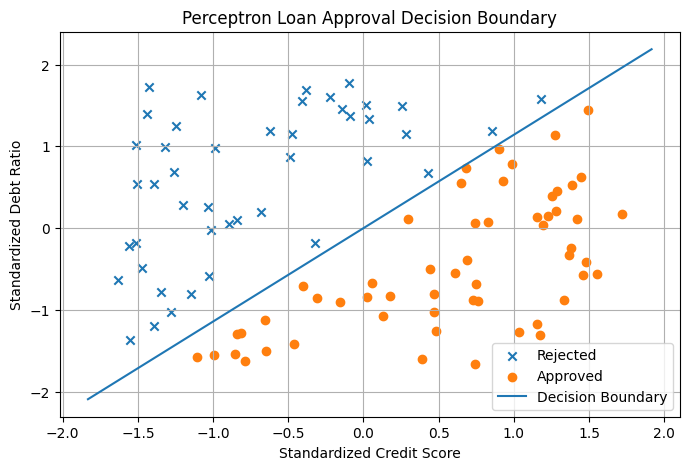

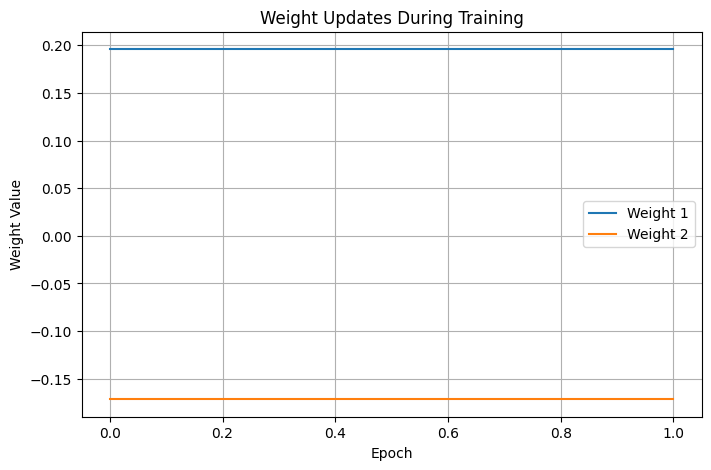

XOR Epoch 1: Errors = 3
XOR Epoch 2: Errors = 3
XOR Epoch 3: Errors = 4
XOR Epoch 4: Errors = 4
XOR Epoch 5: Errors = 4
XOR Epoch 6: Errors = 4
XOR Epoch 7: Errors = 4
XOR Epoch 8: Errors = 4
XOR Epoch 9: Errors = 4
XOR Epoch 10: Errors = 4
XOR Epoch 11: Errors = 4
XOR Epoch 12: Errors = 4
XOR Epoch 13: Errors = 4
XOR Epoch 14: Errors = 4
XOR Epoch 15: Errors = 4
XOR Epoch 16: Errors = 4
XOR Epoch 17: Errors = 4
XOR Epoch 18: Errors = 4
XOR Epoch 19: Errors = 4
XOR Epoch 20: Errors = 4

XOR predictions: [1 1 0 0]
Actual XOR labels: [0 1 1 0]
XOR converged: False


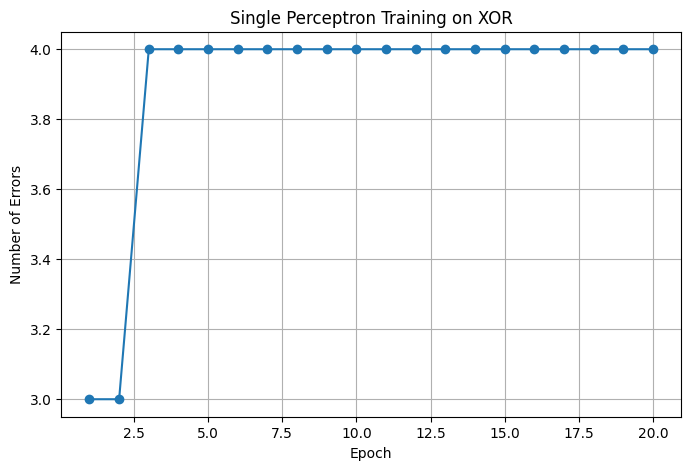


Activation Function Comparison
Input:    [-2 -1  0  1  2]
Step:     [0 0 1 1 1]
Sigmoid:  [0.119 0.269 0.5   0.731 0.881]
ReLU:     [0 0 0 1 2]


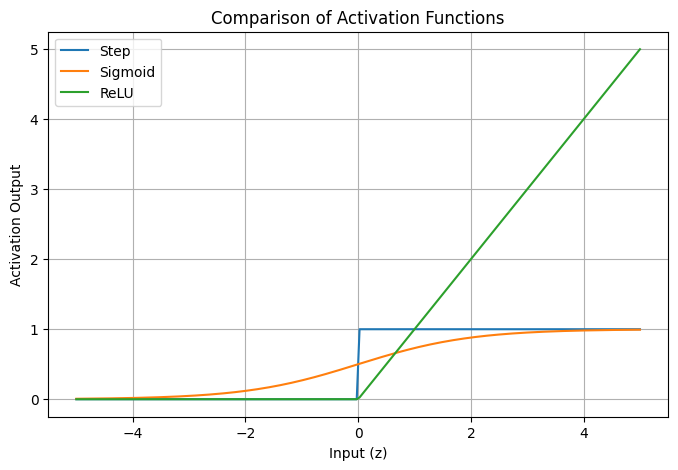

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ==========================================
# TASK 1: Perceptron functions
# ==========================================

def step(z):
    return np.where(z >= 0, 1, 0)

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def relu(z):
    return np.maximum(0, z)

def predict(X, weights, bias):
    z = np.dot(X, weights) + bias
    return step(z)


# ==========================================
# TASK 2: Generate 100 loan applications
# ==========================================

n = 100

credit = np.random.randint(300, 851, n)
debt_ratio = np.random.uniform(0, 1, n)

# Standardize input features
credit_scaled = (credit - credit.mean()) / credit.std()
debt_scaled = (debt_ratio - debt_ratio.mean()) / debt_ratio.std()

X = np.column_stack((credit_scaled, debt_scaled))

# Generate linearly separable loan labels
y = (1.2 * X[:, 0] - 1.1 * X[:, 1] > 0).astype(int)

# Initialize weights and bias
weights = np.zeros(2)
bias = 0.0
learning_rate = 0.1
epochs = 30

weight_history = []
error_history = []

# Perceptron learning rule
for epoch in range(epochs):
    errors = 0

    for i in range(n):
        z = np.dot(X[i], weights) + bias
        prediction = step(z)

        error = y[i] - prediction

        weights += learning_rate * error * X[i]
        bias += learning_rate * error

        if error != 0:
            errors += 1

    weight_history.append(weights.copy())
    error_history.append(errors)

    print(f"Epoch {epoch + 1}: Errors = {errors}, "
          f"Weights = {np.round(weights, 3)}, "
          f"Bias = {bias:.3f}")

    if errors == 0:
        print("Perceptron converged!")
        break

print("\nFinal weights:", weights)
print("Final bias:", bias)

predictions = predict(X, weights, bias)

print("Training accuracy:",
      round(np.mean(predictions == y) * 100, 2), "%")

print("\nLoan Approval Results")
for i in range(5):
    result = "Approved" if predictions[i] == 1 else "Rejected"
    print(f"Credit: {credit[i]}, Debt ratio: {debt_ratio[i]:.2f}, "
          f"Prediction: {result}")


# ==========================================
# TASK 3: Plot decision boundary
# ==========================================

plt.figure(figsize=(8, 5))

plt.scatter(X[y == 0, 0], X[y == 0, 1],
            label="Rejected", marker="x")
plt.scatter(X[y == 1, 0], X[y == 1, 1],
            label="Approved", marker="o")

x1 = np.linspace(X[:, 0].min() - 0.2,
                 X[:, 0].max() + 0.2, 100)

if abs(weights[1]) > 1e-10:
    x2 = -(weights[0] * x1 + bias) / weights[1]
    plt.plot(x1, x2, label="Decision Boundary")

plt.xlabel("Standardized Credit Score")
plt.ylabel("Standardized Debt Ratio")
plt.title("Perceptron Loan Approval Decision Boundary")
plt.legend()
plt.grid(True)
plt.show()


# Plot weight updates per epoch
weight_history = np.array(weight_history)

plt.figure(figsize=(8, 5))
plt.plot(weight_history[:, 0], label="Weight 1")
plt.plot(weight_history[:, 1], label="Weight 2")
plt.xlabel("Epoch")
plt.ylabel("Weight Value")
plt.title("Weight Updates During Training")
plt.legend()
plt.grid(True)
plt.show()


# ==========================================
# TASK 4: XOR dataset
# ==========================================

X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_xor = np.array([0, 1, 1, 0])

w = np.zeros(2)
b = 0.0
lr = 0.1
xor_errors = []

for epoch in range(20):
    errors = 0

    for i in range(4):
        pred = step(np.dot(X_xor[i], w) + b)
        error = y_xor[i] - pred

        w += lr * error * X_xor[i]
        b += lr * error

        if error != 0:
            errors += 1

    xor_errors.append(errors)

    print(f"XOR Epoch {epoch + 1}: Errors = {errors}")

print("\nXOR predictions:", predict(X_xor, w, b))
print("Actual XOR labels:", y_xor)
print("XOR converged:", xor_errors[-1] == 0)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 21), xor_errors, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Number of Errors")
plt.title("Single Perceptron Training on XOR")
plt.grid(True)
plt.show()


# ==========================================
# TASK 5: Compare activation functions
# ==========================================

inputs = np.array([-2, -1, 0, 1, 2])

print("\nActivation Function Comparison")
print("Input:   ", inputs)
print("Step:    ", step(inputs))
print("Sigmoid: ", np.round(sigmoid(inputs), 3))
print("ReLU:    ", relu(inputs))

z = np.linspace(-5, 5, 200)

plt.figure(figsize=(8, 5))
plt.plot(z, step(z), label="Step")
plt.plot(z, sigmoid(z), label="Sigmoid")
plt.plot(z, relu(z), label="ReLU")

plt.xlabel("Input (z)")
plt.ylabel("Activation Output")
plt.title("Comparison of Activation Functions")
plt.legend()
plt.grid(True)
plt.show()


 XOR Dataset
Final loss: 0.0007
Accuracy: 100.0 %
Predictions:
[0 1 1 0]

 Two-Moons Dataset
Final loss: 0.0084
Accuracy: 100.0 %
Predictions:
[0 0 1 0 0 0 1 0 0 1 0 0 1 1 1 0 0 0 0 0 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 0 0
 1 1 0 1 1 1 0 1 1 1 1 1 1 0 0 1 1 0 1 1 0 1 1 0 0 0 1 1 1 1 0 1 1 0 1 0 1
 1 1 0 1 0 0 1 0 0 1 1 1 0 1 0 0 0 1 0 1 0 1 0 0 0 0 0 0 1 1 0 0 0 0 1 1 1
 1 1 0 1 0 1 0 1 1 0 0 0 0 0 0 0 1 0 0 0 0 1 1 1 1 0 0 1 0 0 0 0 0 0 0 1 0
 1 0 0 1 1 1 0 0 1 1 0 1 1 0 0 0 0 0 1 0 1 1 1 0 0 1 1 0 1 0 0 1 1 0 0 0 1
 1 1 1 0 1 1 0 1 0 0 1 0 0 1 1 1 1 0 0 1 0 1 1 1 0 1 1 1 1 0 0 1 1 0 0 0 1
 0 1 0 1 1 0 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 0 1 1 1 0 1 1 0 0 0 1 0 1 0
 1 0 0 0 0 1 0 0 1 1 1 0 0 0 0 0 0 1 1 0 1 0 0 1 0 1 0 0 1 0 0 0 1 1 1 1 0
 0 0 1 0]


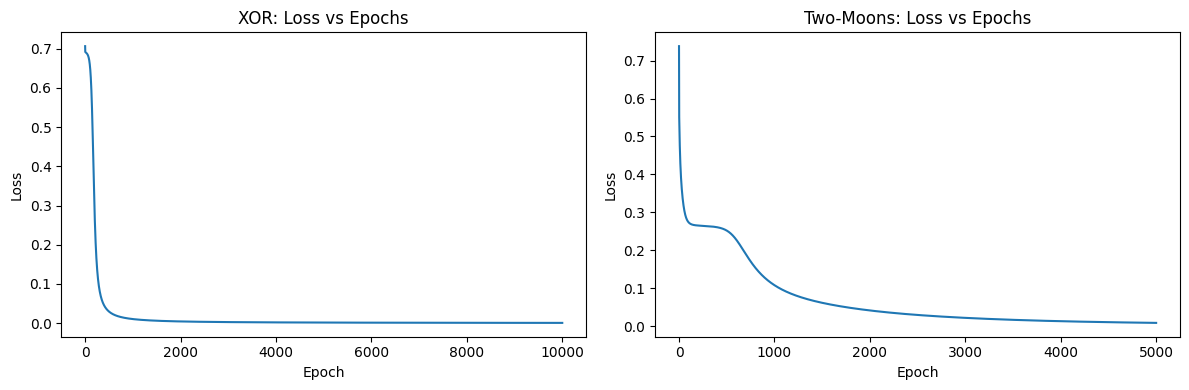

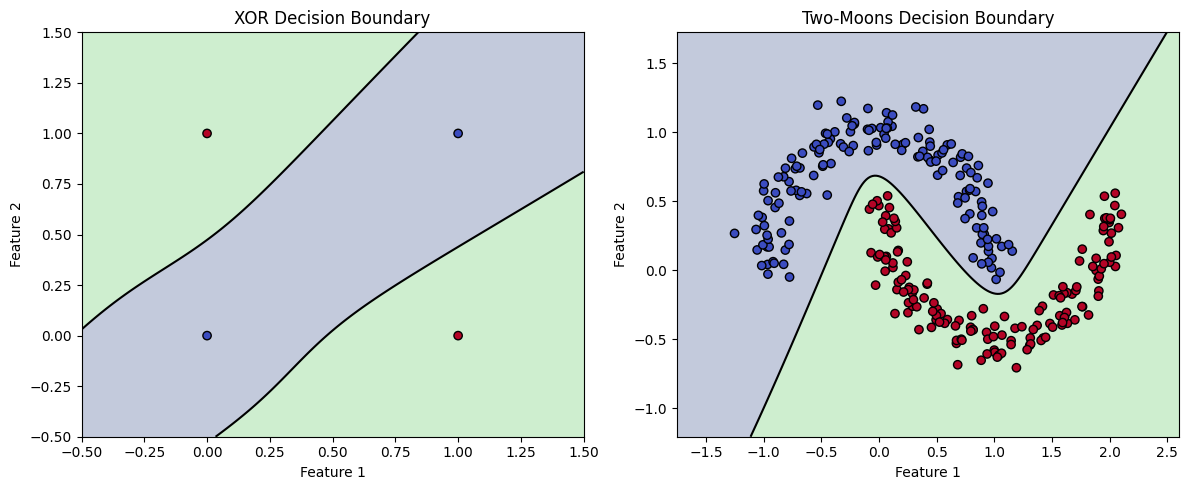


Gradient Verification
Analytical gradient: -0.03551549858186377
Numerical gradient:  -0.035515498580940275
Absolute difference: 9.23497389671013e-13


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Sigmoid activation function
def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))


# Create XOR dataset
X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y_xor = np.array([[0], [1], [1], [0]], dtype=float)


# Create two-moons dataset using NumPy
n = 300
t = np.linspace(0, np.pi, n // 2)

moon1 = np.column_stack((np.cos(t), np.sin(t)))
moon2 = np.column_stack((1 - np.cos(t), 0.5 - np.sin(t)))

X_moons = np.vstack((moon1, moon2))
X_moons += np.random.normal(0, 0.10, X_moons.shape)

y_moons = np.vstack((
    np.zeros((n // 2, 1)),
    np.ones((n // 2, 1))
))

# Shuffle the moon data
indices = np.random.permutation(n)
X_moons = X_moons[indices]
y_moons = y_moons[indices]


# Initialize weights and biases
def initialize(input_size, hidden_size):
    W1 = np.random.randn(input_size, hidden_size) * 0.5
    b1 = np.zeros((1, hidden_size))
    W2 = np.random.randn(hidden_size, 1) * 0.5
    b2 = np.zeros((1, 1))
    return W1, b1, W2, b2


# Forward propagation
def forward(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = sigmoid(Z1)

    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)

    return A1, A2


# Binary cross-entropy loss
def calculate_loss(y, predictions):
    predictions = np.clip(predictions, 1e-9, 1 - 1e-9)

    loss = -np.mean(
        y * np.log(predictions)
        + (1 - y) * np.log(1 - predictions)
    )
    return loss


# Backpropagation using the chain rule
def backward(X, y, A1, A2, W2):
    m = len(X)

    dZ2 = (A2 - y) / m
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dZ1 = (dZ2 @ W2.T) * A1 * (1 - A1)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2


# Train the neural network
def train_network(X, y, hidden_size=8, epochs=5000, lr=1.0):
    W1, b1, W2, b2 = initialize(X.shape[1], hidden_size)
    losses = []

    for epoch in range(epochs):
        # Forward pass
        A1, A2 = forward(X, W1, b1, W2, b2)

        # Calculate loss
        loss = calculate_loss(y, A2)
        losses.append(loss)

        # Backward pass
        dW1, db1, dW2, db2 = backward(X, y, A1, A2, W2)

        # Gradient descent updates
        W1 -= lr * dW1
        b1 -= lr * db1
        W2 -= lr * dW2
        b2 -= lr * db2

    return W1, b1, W2, b2, losses


# Train on XOR dataset
xor_model = train_network(
    X_xor, y_xor, hidden_size=8, epochs=10000, lr=1.0
)

# Train on two-moons dataset
moon_model = train_network(
    X_moons, y_moons, hidden_size=12, epochs=5000, lr=1.0
)


# Display predictions
def show_results(name, X, y, model):
    W1, b1, W2, b2, losses = model
    _, predictions = forward(X, W1, b1, W2, b2)
    classes = (predictions >= 0.5).astype(int)
    accuracy = np.mean(classes == y) * 100

    print("\n", name)
    print("Final loss:", round(losses[-1], 4))
    print("Accuracy:", round(accuracy, 2), "%")

    print("Predictions:")
    print(classes.ravel())

    return losses


xor_losses = show_results("XOR Dataset", X_xor, y_xor, xor_model)
moon_losses = show_results("Two-Moons Dataset", X_moons, y_moons, moon_model)


# Plot loss against epochs
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(xor_losses)
plt.title("XOR: Loss vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(moon_losses)
plt.title("Two-Moons: Loss vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()


# Plot nonlinear decision boundary
def plot_boundary(X, y, model, title):
    W1, b1, W2, b2, losses = model

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.column_stack((xx.ravel(), yy.ravel()))
    _, predictions = forward(grid, W1, b1, W2, b2)
    predictions = predictions.reshape(xx.shape)

    plt.contourf(xx, yy, predictions, levels=[0, 0.5, 1], alpha=0.3)
    plt.contour(xx, yy, predictions, levels=[0.5], colors="black")
    plt.scatter(
        X[:, 0], X[:, 1],
        c=y.ravel(), edgecolors="black", cmap="coolwarm"
    )

    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plot_boundary(X_xor, y_xor, xor_model, "XOR Decision Boundary")

plt.subplot(1, 2, 2)
plot_boundary(X_moons, y_moons, moon_model, "Two-Moons Decision Boundary")

plt.tight_layout()
plt.show()


# Numerical gradient verification for one weight
X = X_moons
y = y_moons

W1, b1, W2, b2 = initialize(2, 12)

A1, A2 = forward(X, W1, b1, W2, b2)
dW1, db1, dW2, db2 = backward(X, y, A1, A2, W2)

# Analytical gradient of W1[0, 0]
analytical = dW1[0, 0]

# Numerical gradient using a small change
epsilon = 1e-5

W1[0, 0] += epsilon
_, A_plus = forward(X, W1, b1, W2, b2)
loss_plus = calculate_loss(y, A_plus)

W1[0, 0] -= 2 * epsilon
_, A_minus = forward(X, W1, b1, W2, b2)
loss_minus = calculate_loss(y, A_minus)

numerical = (loss_plus - loss_minus) / (2 * epsilon)

print("\nGradient Verification")
print("Analytical gradient:", analytical)
print("Numerical gradient: ", numerical)
print("Absolute difference:", abs(analytical - numerical))

Sample dataset:
   Tenure  MonthlyCharges    ContractType  Complaints  DataUsage  Churn
0      52      107.178357        One-year           4   4.820565      1
1      15       41.921399  Month-to-month           1  88.009233      0
2      72      117.586526  Month-to-month           2  32.178390      0
3      61       53.689579        Two-year           2  13.768912      0
4      21       38.211792        One-year           0  47.377662      0

Churn counts:
Churn
0    1056
1     444
Name: count, dtype: int64

Training data shape: (1200, 7)
Testing data shape: (300, 7)


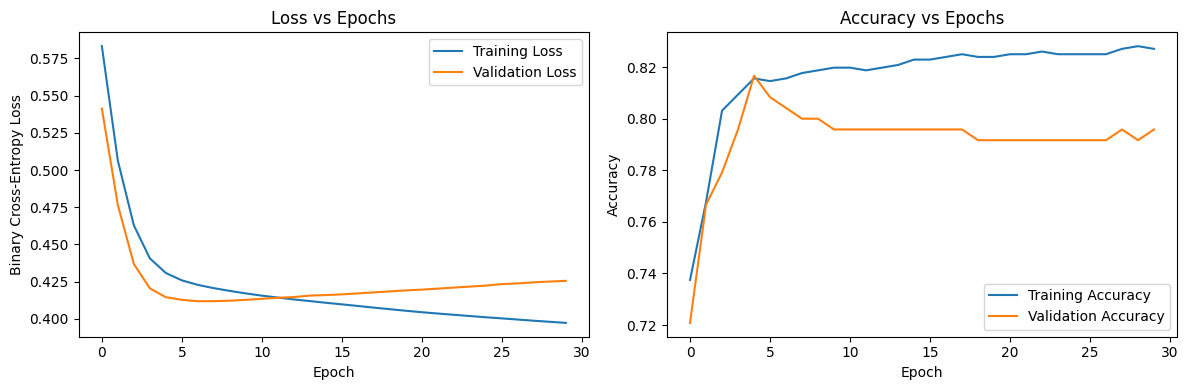


MLP Evaluation Results
Accuracy : 0.7567
Precision: 0.6538
Recall   : 0.382
F1-score : 0.4823


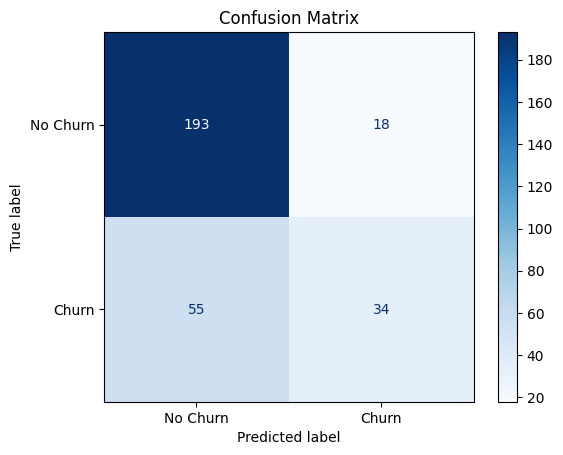


Effect of Hidden-Layer Width:
 Hidden Width  Accuracy  Precision  Recall  F1-score  Final Validation Loss
           16    0.7633     0.6731  0.3933    0.4965                 0.4117
           32    0.7500     0.6346  0.3708    0.4681                 0.4156
           64    0.7533     0.6364  0.3933    0.4861                 0.4190


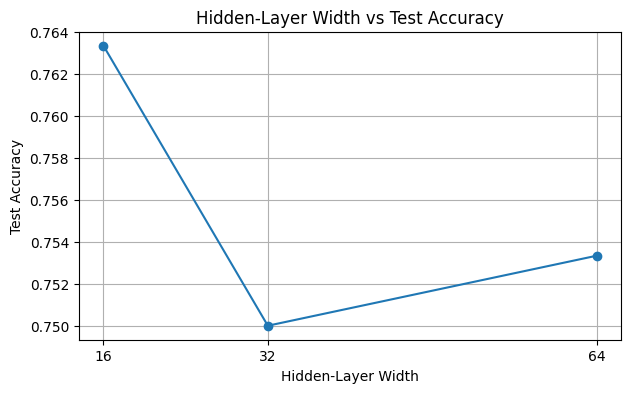

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# --------------------------------------------------
# 1. CREATE SAMPLE CUSTOMER-CHURN DATASET
# --------------------------------------------------

n = 1500

df = pd.DataFrame({
    "Tenure": np.random.randint(1, 73, n),
    "MonthlyCharges": np.random.uniform(20, 120, n),
    "ContractType": np.random.choice(
        ["Month-to-month", "One-year", "Two-year"],
        n, p=[0.55, 0.25, 0.20]
    ),
    "Complaints": np.random.poisson(1.5, n),
    "DataUsage": np.random.uniform(1, 100, n)
})

# Generate churn labels using a probability model
score = (
    1.0
    - 0.045 * df["Tenure"].to_numpy()
    + 0.025 * (df["MonthlyCharges"].to_numpy() - 70)
    + 0.55 * df["Complaints"].to_numpy()
    - 0.025 * df["DataUsage"].to_numpy()
    + np.where(df["ContractType"] == "Month-to-month", 1.2, 0)
    + np.where(df["ContractType"] == "One-year", -0.3, -1.0)
)

probability = 1 / (1 + np.exp(-score))
df["Churn"] = np.random.binomial(1, probability)

print("Sample dataset:")
print(df.head())
print("\nChurn counts:")
print(df["Churn"].value_counts())

# --------------------------------------------------
# 2. SEPARATE FEATURES AND TARGET
# --------------------------------------------------

X = df.drop("Churn", axis=1)
y = df["Churn"]

numeric_features = [
    "Tenure", "MonthlyCharges", "Complaints", "DataUsage"
]
categorical_features = ["ContractType"]

# Split data before preprocessing to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale numeric data and encode categorical data
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore",
                                  sparse_output=False),
     categorical_features)
])

X_train = preprocessor.fit_transform(X_train).astype("float32")
X_test = preprocessor.transform(X_test).astype("float32")

y_train = y_train.to_numpy().astype("float32")
y_test = y_test.to_numpy().astype("float32")

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# --------------------------------------------------
# 3. BUILD MLP MODEL
# --------------------------------------------------

def build_model(width=32):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(width, activation="relu"),
        tf.keras.layers.Dense(width // 2, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Train the main model
model = build_model(width=32)

history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# --------------------------------------------------
# 4. PLOT TRAINING AND VALIDATION CURVES
# --------------------------------------------------

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 5. EVALUATE THE MODEL
# --------------------------------------------------

predicted_probabilities = model.predict(X_test, verbose=0).ravel()
y_pred = (predicted_probabilities >= 0.5).astype(int)

print("\nMLP Evaluation Results")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred,
                                          zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred,
                                       zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred,
                                  zero_division=0), 4))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)
display.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# --------------------------------------------------
# 6. VARY THE HIDDEN-LAYER WIDTH
# --------------------------------------------------

widths = [16, 32, 64]
results = []

for width in widths:
    tf.keras.backend.clear_session()
    tf.random.set_seed(42)

    test_model = build_model(width=width)

    test_history = test_model.fit(
        X_train, y_train,
        epochs=30,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    probabilities = test_model.predict(X_test, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Hidden Width": width,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "Final Validation Loss": test_history.history["val_loss"][-1]
    })

results_df = pd.DataFrame(results)

print("\nEffect of Hidden-Layer Width:")
print(results_df.round(4).to_string(index=False))

# Plot accuracy for different widths
plt.figure(figsize=(7, 4))
plt.plot(
    results_df["Hidden Width"],
    results_df["Accuracy"],
    marker="o"
)
plt.title("Hidden-Layer Width vs Test Accuracy")
plt.xlabel("Hidden-Layer Width")
plt.ylabel("Test Accuracy")
plt.xticks(widths)
plt.grid(True)
plt.show()

Dataset sample:
         Age        BMI     Glucose  BloodPressure    Insulin   Activity  \
0  50.960570  32.630888  147.987109      84.340333  76.368760  35.706130   
1  43.340828  37.547083  138.492674      68.385771  94.941847  39.681847   
2  52.772262  21.007162  121.192607      65.181613  72.265303  26.686916   
3  63.276358  30.814846  107.061264      74.959507  89.221346  23.877633   
4  42.190160  24.746787  133.964466      72.957785  33.723487  19.148495   

   Diabetes  
0         1  
1         0  
2         1  
3         0  
4         1  

Class distribution:
Diabetes
1    406
0     94
Name: count, dtype: int64


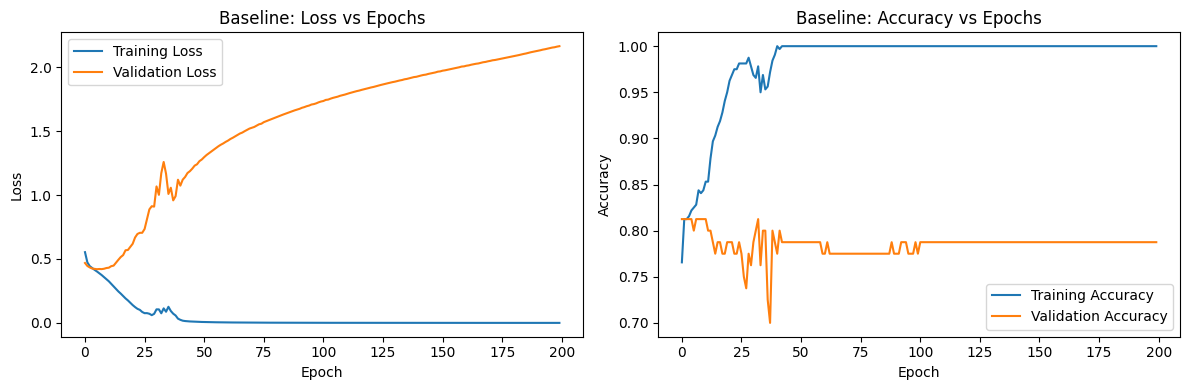

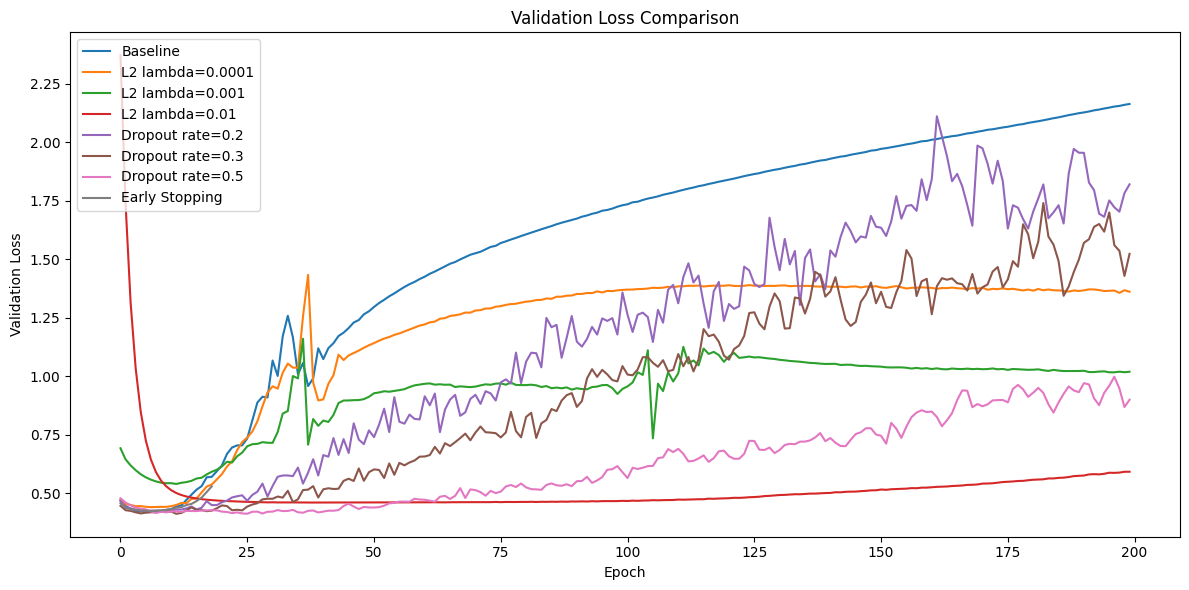


Model Comparison:
           Model  Train Accuracy  Test Accuracy  Train-Test Gap  Epochs
        Baseline           95.75           82.0           13.75     200
L2 lambda=0.0001           95.50           80.0           15.50     200
 L2 lambda=0.001           95.25           79.0           16.25     200
  L2 lambda=0.01           88.75           78.0           10.75     200
Dropout rate=0.2           95.75           80.0           15.75     200
Dropout rate=0.3           95.50           82.0           13.50     200
Dropout rate=0.5           93.25           79.0           14.25     200
  Early Stopping           84.25           79.0            5.25      19


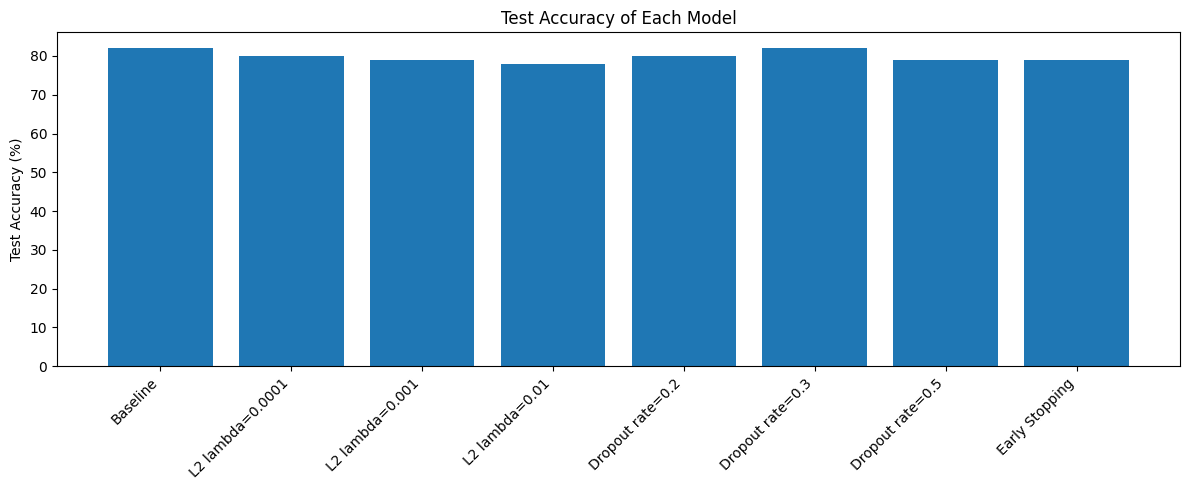

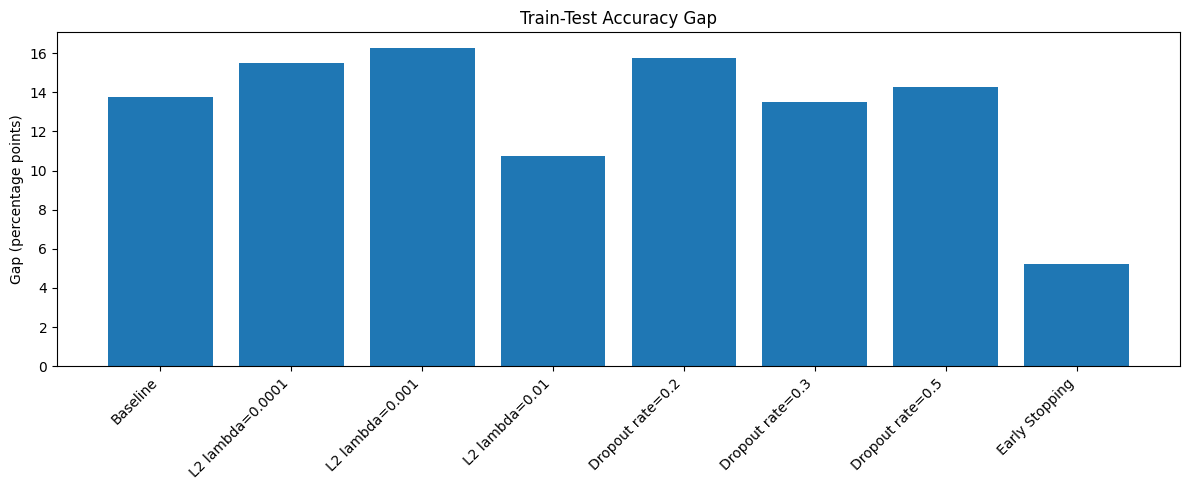

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# --------------------------------------------------
# 1. CREATE A SMALL SIMULATED DIABETES DATASET
# --------------------------------------------------

n = 500

X = np.column_stack([
    np.random.normal(45, 12, n),    # Age
    np.random.normal(28, 5, n),     # BMI
    np.random.normal(120, 20, n),   # Glucose
    np.random.normal(75, 12, n),    # Blood pressure
    np.random.normal(100, 35, n),   # Insulin
    np.random.normal(30, 10, n)     # Activity level
])

# Generate binary labels using a simulated risk relationship
risk = (
    -5
    + 0.035 * X[:, 0]
    + 0.07 * X[:, 1]
    + 0.025 * X[:, 2]
    + 0.006 * X[:, 4]
    - 0.025 * X[:, 5]
)

probability = 1 / (1 + np.exp(-risk))
y = np.random.binomial(1, probability, n)

feature_names = [
    "Age", "BMI", "Glucose",
    "BloodPressure", "Insulin", "Activity"
]

df = pd.DataFrame(X, columns=feature_names)
df["Diabetes"] = y

print("Dataset sample:")
print(df.head())
print("\nClass distribution:")
print(df["Diabetes"].value_counts())

# --------------------------------------------------
# 2. SPLIT AND SCALE DATA
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype("float32")
X_test = scaler.transform(X_test).astype("float32")

y_train = y_train.astype("float32")
y_test = y_test.astype("float32")

# --------------------------------------------------
# 3. BUILD THE LARGE MLP
# --------------------------------------------------

def build_model(l2_value=0.0, dropout_rate=0.0):
    regularizer = (
        tf.keras.regularizers.l2(l2_value)
        if l2_value > 0 else None
    )

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),

        tf.keras.layers.Dense(
            256, activation="relu",
            kernel_regularizer=regularizer
        ),
        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Dense(
            128, activation="relu",
            kernel_regularizer=regularizer
        ),
        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Dense(
            64, activation="relu",
            kernel_regularizer=regularizer
        ),

        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Store results and histories
results = []
histories = {}

# --------------------------------------------------
# 4. BASELINE MODEL WITHOUT REGULARISATION
# --------------------------------------------------

tf.keras.backend.clear_session()
tf.random.set_seed(42)

baseline = build_model()
hist = baseline.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=16,
    verbose=0
)

histories["Baseline"] = hist.history

train_loss, train_acc = baseline.evaluate(
    X_train, y_train, verbose=0
)
test_loss, test_acc = baseline.evaluate(
    X_test, y_test, verbose=0
)

results.append({
    "Model": "Baseline",
    "Train Accuracy": train_acc,
    "Test Accuracy": test_acc,
    "Train-Test Gap": train_acc - test_acc,
    "Epochs": len(hist.history["loss"])
})

# --------------------------------------------------
# 5. L2 REGULARISATION: THREE LAMBDA VALUES
# --------------------------------------------------

for lam in [0.0001, 0.001, 0.01]:
    tf.keras.backend.clear_session()
    tf.random.set_seed(42)

    model = build_model(l2_value=lam)

    hist = model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=200,
        batch_size=16,
        verbose=0
    )

    train_loss, train_acc = model.evaluate(
        X_train, y_train, verbose=0
    )
    test_loss, test_acc = model.evaluate(
        X_test, y_test, verbose=0
    )

    name = f"L2 lambda={lam}"
    histories[name] = hist.history

    results.append({
        "Model": name,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Train-Test Gap": train_acc - test_acc,
        "Epochs": len(hist.history["loss"])
    })

# --------------------------------------------------
# 6. DROPOUT: THREE DROPOUT RATES
# --------------------------------------------------

for rate in [0.2, 0.3, 0.5]:
    tf.keras.backend.clear_session()
    tf.random.set_seed(42)

    model = build_model(dropout_rate=rate)

    hist = model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=200,
        batch_size=16,
        verbose=0
    )

    train_loss, train_acc = model.evaluate(
        X_train, y_train, verbose=0
    )
    test_loss, test_acc = model.evaluate(
        X_test, y_test, verbose=0
    )

    name = f"Dropout rate={rate}"
    histories[name] = hist.history

    results.append({
        "Model": name,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Train-Test Gap": train_acc - test_acc,
        "Epochs": len(hist.history["loss"])
    })

# --------------------------------------------------
# 7. EARLY STOPPING
# --------------------------------------------------

tf.keras.backend.clear_session()
tf.random.set_seed(42)

early_model = build_model()

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

early_hist = early_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0
)

histories["Early Stopping"] = early_hist.history

train_loss, train_acc = early_model.evaluate(
    X_train, y_train, verbose=0
)
test_loss, test_acc = early_model.evaluate(
    X_test, y_test, verbose=0
)

results.append({
    "Model": "Early Stopping",
    "Train Accuracy": train_acc,
    "Test Accuracy": test_acc,
    "Train-Test Gap": train_acc - test_acc,
    "Epochs": len(early_hist.history["loss"])
})

# --------------------------------------------------
# 8. PLOT BASELINE OVERFITTING
# --------------------------------------------------

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(histories["Baseline"]["loss"], label="Training Loss")
plt.plot(histories["Baseline"]["val_loss"], label="Validation Loss")
plt.title("Baseline: Loss vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(histories["Baseline"]["accuracy"], label="Training Accuracy")
plt.plot(histories["Baseline"]["val_accuracy"], label="Validation Accuracy")
plt.title("Baseline: Accuracy vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 9. PLOT VALIDATION LOSS FOR ALL MODELS
# --------------------------------------------------

plt.figure(figsize=(12, 6))

for name, history in histories.items():
    plt.plot(history["val_loss"], label=name)

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 10. COMPARE TEST ACCURACY AND TRAIN-TEST GAP
# --------------------------------------------------

results_df = pd.DataFrame(results)

# Convert metrics to percentages
for col in ["Train Accuracy", "Test Accuracy", "Train-Test Gap"]:
    results_df[col] = results_df[col] * 100

print("\nModel Comparison:")
print(results_df.round(2).to_string(index=False))

# Plot test accuracy
plt.figure(figsize=(12, 5))
plt.bar(results_df["Model"], results_df["Test Accuracy"])
plt.title("Test Accuracy of Each Model")
plt.ylabel("Test Accuracy (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Plot train-test gap
plt.figure(figsize=(12, 5))
plt.bar(results_df["Model"], results_df["Train-Test Gap"])
plt.title("Train-Test Accuracy Gap")
plt.ylabel("Gap (percentage points)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()